# Методы кластеризации



## Часть 1: семинар и домашняя работа

Готовые ячейки можно выполнять по порядку и использовать для показа.
В домашней части замените `YOUR CODE` своим кодом. 

 Во второй части перейдём к котикам.

In [6]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import (
    AgglomerativeClustering, DBSCAN, KMeans, SpectralClustering
)
from sklearn.datasets import load_digits, make_blobs, make_circles, make_moons
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler, normalize

seed = 42
np.random.seed(seed)

# K-Means by hands

В этом разделе мы реализруем алгоритм K-Means самостоятельно. Напомним, как вообще выглядит алгоритм:

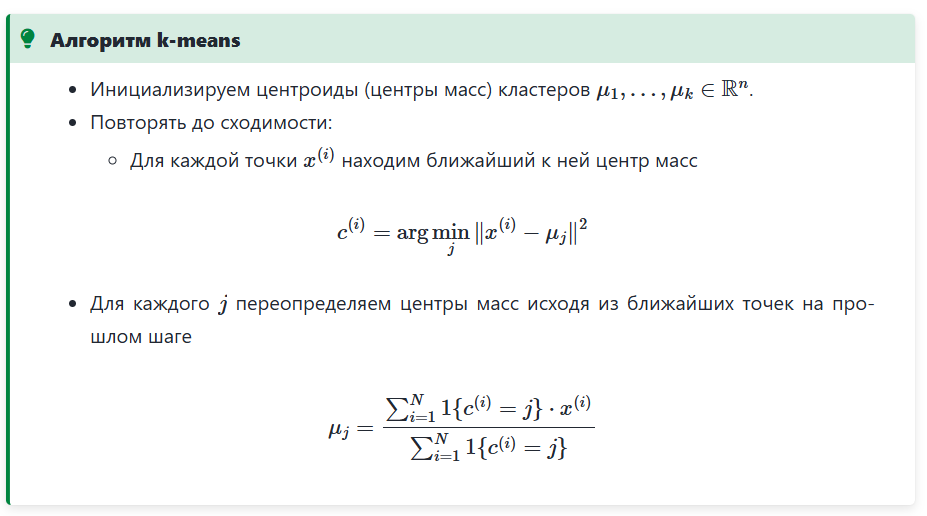

### Домашняя часть 1: реализовать KMeans

Заполните `fit` и `predict`. В `fit` выберите начальные центры из `X` через
`np.random.default_rng(42).choice(len(X), self.k, replace=False)`.
Чередуйте назначение точек ближайшим центрам и пересчёт центров как средних.
Если кластер пуст, сохраните его прежний центр. Остановитесь при смещении
всех координат центров меньше `tol` или после `max_iters` итераций.

`fit` сохраняет центры в `self.centroids` и возвращает `self`.
`predict` возвращает массив номеров ближайших кластеров для переданных точек.
Пока задание не заполнено, готовый пример sklearn и следующие разделы работают.

In [7]:
class KMeansCustom:
    def __init__(self, k=3, max_iters=1000, tol=1e-4):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.centroids = None

    def fit(self, X):
        self.centroids = X[np.random.default_rng(42).choice(X.shape[0], self.k, replace=False)].astype(float)
        for _ in range(self.max_iters):
            labels = np.argmin(np.sum((self.centroids[None, :, :] - X[:, None, :]) ** 2, axis = 2), axis = 1).astype(int)
            new_centroids = np.zeros((self.k, X.shape[1])).astype(float)
            for i in range(X.shape[0]):
                labels[i] = np.argmin(np.sum((self.centroids - X[i]) ** 2, axis=1))
            for i in range(self.k):
                points = X[labels == i]
                if len(points) == 0:
                    new_centroids[i] = X[np.random.default_rng(42).choice(X.shape[0])]
                else:
                    new_centroids[i] = points.mean(axis = 0)
            if abs(new_centroids - self.centroids).max() < self.tol:
                break
            self.centroids = new_centroids
        return self

    def predict(self, X):
        labels = np.argmin(np.sum((self.centroids[None, :, :] - X[:, None, :]) ** 2, axis = 2), axis = 1).astype(int)
        return labels

Давайте сравним наш алгоритм с уже реализованным алгоритмом в `sklearn`.

Подготовим данные.

In [8]:
X, _ = make_blobs(
    n_samples=5_000, centers=3, cluster_std=[2, 1.8, 3.5], random_state=42)

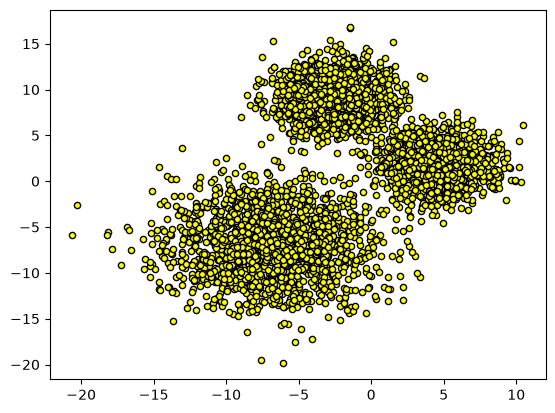

In [9]:
plt.scatter(X[:, 0], X[:, 1], s=20, edgecolors='black', color='yellow')
plt.show()

In [10]:
my_km = KMeansCustom(k=3, max_iters=10_000, tol=1e-4)
start = time.perf_counter()
my_km.fit(X)
my_time = time.perf_counter() - start
my_labels = my_km.predict(X)

indices = np.random.default_rng(42).choice(len(X), 3, replace=False)
sk_km = KMeans(
    n_clusters=3, init=X[indices], n_init=1, max_iter=10_000,
    tol=1e-4, random_state=42,
)
start = time.perf_counter()
sk_km.fit(X)
sk_time = time.perf_counter() - start

print("--- Результаты (на 10к точках) ---")
if my_labels is None:
    print("Сначала заполните YOUR CODE в KMeansCustom.")
else:
    assert np.asarray(my_labels).shape == (len(X),)
    print(f"Твой код:    {my_time:.4f} сек")
    print("\nЦентроиды (Твои):\n", my_km.centroids)
print(f"Sklearn:     {sk_time:.4f} сек")
print("\nЦентроиды (Sklearn):\n", sk_km.cluster_centers_)

ValueError: setting an array element with a sequence.

Для сравнения используются 10 000 точек и одинаковые начальные центры.
Критерии остановки реализаций могут немного различаться. Один замер времени
недостаточен для вывода о скорости: повторите его несколько раз.

Давайте посмотрим на графики

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
if my_labels is None:
    ax1.text(0.5, 0.5, "Заполните YOUR CODE", ha="center", va="center")
else:
    ax1.scatter(X[:, 0], X[:, 1], c=my_labels, s=30, cmap='viridis')
    ax1.scatter(
        my_km.centroids[:, 0], my_km.centroids[:, 1], c='red',
        s=200, alpha=0.5, marker='X', label='Центроиды',
    )
    ax1.legend()
ax1.set_title("Собственная реализация KMeans")
ax2.scatter(X[:, 0], X[:, 1], c=sk_km.labels_, s=30, cmap='viridis')
ax2.scatter(
    sk_km.cluster_centers_[:, 0], sk_km.cluster_centers_[:, 1], c='red',
    s=200, alpha=0.5, marker='X', label='Центроиды',
)
ax2.set_title("KMeans из Scikit-Learn")
ax2.legend()
plt.show()

**Готовая демонстрация.** Анимация использует sklearn и не зависит от вашей
реализации. На каждом кадре выполняется один шаг алгоритма.

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

centers = X[np.random.default_rng(4).choice(len(X), 3, replace=False)]
history = [centers.copy()]
for _ in range(10):
    step = KMeans(n_clusters=3, init=centers, n_init=1, max_iter=1)
    step.fit(X)
    history.append(step.cluster_centers_.copy())
    if np.allclose(centers, history[-1], atol=1e-4, rtol=0):
        break
    centers = history[-1]

fig, ax = plt.subplots(figsize=(8, 5))


def update(frame):
    ax.clear()
    centers = history[frame]
    distances = np.linalg.norm(X[:, None] - centers, axis=2)
    labels = distances.argmin(axis=1)
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', alpha=0.5)
    ax.scatter(
        centers[:, 0], centers[:, 1], c='red', s=200, marker='X',
        edgecolors='black', label='Центроиды',
    )
    ax.set_title(f"K-Means Итерация: {frame}")
    ax.set_xticks([])
    ax.set_yticks([])


animation = FuncAnimation(fig, update, frames=len(history), interval=600)
plt.close(fig)
HTML(animation.to_jshtml())

---
# Toy Examples

Для начала давайте попробуем посмотреть некоторые игрушечные примеры и протестируем различные алгоритмы кластеризации.

## Подгрузка данных

Мы с вами 5 разных примеров различных датасетов:

Давайте посмотрим, как выглядят наши данные.

In [ ]:
N = 6000


X_blobs, y_blobs = make_blobs(n_samples=N, centers=4, cluster_std=0.8, random_state=42)


X_raw, y_aniso = make_blobs(n_samples=N, centers=3, random_state=42)
T = np.array([[0.6, -0.6], [-0.4, 0.8]])
X_aniso = X_raw @ T


X_circles, y_circles = make_circles(n_samples=N, factor=0.5, noise=0.05, random_state=42)


X_moons, y_moons = make_moons(n_samples=N, noise=0.07, random_state=42)


rng = np.random.default_rng(42)
c1 = rng.normal([0, 0], 0.3, (150, 2))
c2 = rng.normal([4, 0], 1.2, (300, 2))
c3 = rng.normal([2, 4], 0.5, (100, 2))
noise_pts = rng.uniform(-2, 6, (50, 2))
X_density = np.vstack([c1, c2, c3, noise_pts])
y_density = np.array([0]*150 + [1]*300 + [2]*100 + [-1]*50)

datasets = [
    (X_blobs,   y_blobs,   'Isotropic Blobs',          4),
    (X_aniso,   y_aniso,   'Anisotropic Blobs',         3),
    (X_circles, y_circles, 'Concentric Circles',        2),
    (X_moons,   y_moons,   'Two Moons',                 2),
    (X_density, y_density, 'Variable Density + Noise',  3),
]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, (X, y, title, _) in zip(axes, datasets):
    unique = np.unique(y)
    for c in unique:
        mask = y == c
        color = 'lightgray' if c == -1 else plt.cm.tab10(int(c))
        ax.scatter(X[mask, 0], X[mask, 1], s=12, color=color, alpha=0.7)
    ax.set_title(title, fontsize=10)
    ax.axis('equal'); ax.axis('off')

plt.suptitle('Five Synthetic Datasets (ground truth labels)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## Тестирование алгоритмов

Далее мы посмотрим несколько различных алгоритмов и как они работают. Мы будем пользоваться библиотекой `sklearn`. Давайте посмотрим, какие вообще есть [функции](https://scikit-learn.org/stable/modules/clustering.html#k-means) там.

### KMeans

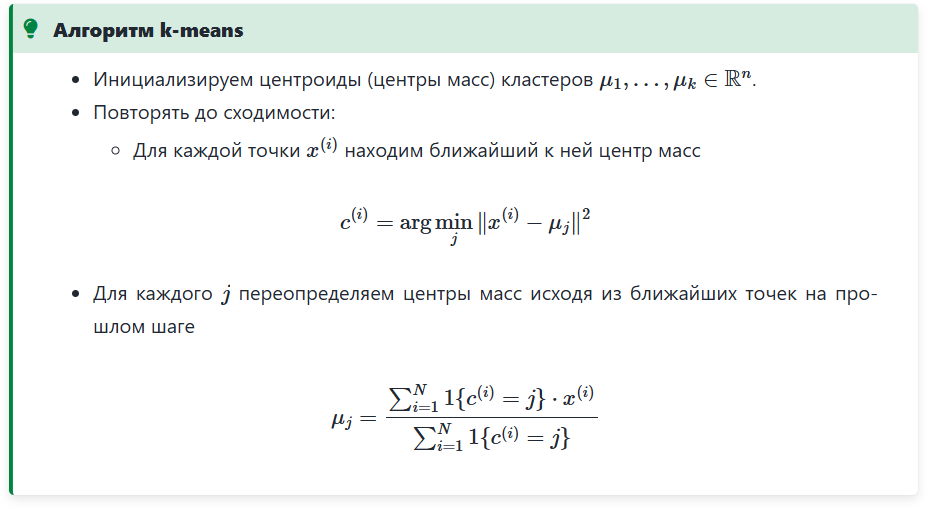

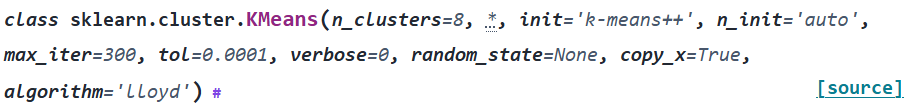

Мы уже знаем про количество кластеров, параметры `max_iter` и `tol`. `init='k-means++'` -- более умная, чем просто рандомная инициализация. Первый центроид выбирается **случайно**, а каждый следующий — **максимально далеко** от уже существующих.

Уточнение к описанию `k-means++`: следующий центр выбирается случайно,
с вероятностью, пропорциональной квадрату расстояния до ближайшего выбранного
центра. Это не обязательный выбор самой далёкой точки.

### DBSCAN

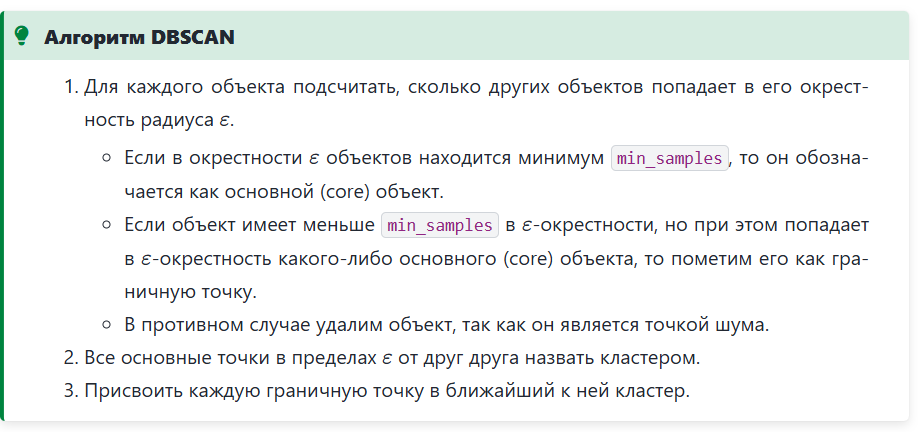

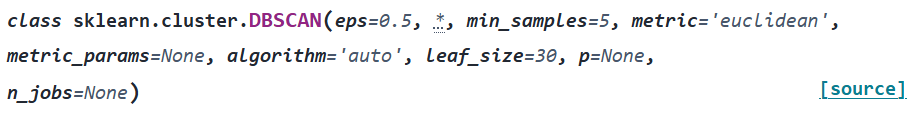

### Тест

Давайте протестируем алгоритмы

**Готовая демонстрация.** Параметры здесь фиксированы, а число групп для части
алгоритмов взято из генератора. Это сравнение формы кластеров при данных настройках.
ARI считаем на всех точках, включая точки с меткой `-1`; не исключаем ошибки
алгоритма вместе с найденным шумом. В этом расчёте `-1` считается отдельной группой.

Спектральная кластеризация строит граф 10 ближайших соседей. Число соседей и масштаб признаков влияют на результат. Предупреждение `Graph is not fully connected` означает, что граф распался на компоненты: если их число совпадает с заданным числом кластеров, такое разбиение естественно.

In [ ]:
def make_algorithms(k):
    return {
        'K-Means': KMeans(n_clusters=k, random_state=42, n_init=10),
        'Agglom. (Avg)': AgglomerativeClustering(n_clusters=k, linkage='average'),
        'Spectral': SpectralClustering(
            n_clusters=k, affinity='nearest_neighbors', n_neighbors=10,
            eigen_solver='lobpcg', random_state=42,
        ),
        'DBSCAN': DBSCAN(eps=0.2, min_samples=2),
    }


algo_names = list(make_algorithms(2))
fig, axes = plt.subplots(
    len(datasets), len(algo_names), figsize=(12, 12)
)
score_table = []

for row, (X, y_true, ds_name, k) in enumerate(datasets):
    X_sc = StandardScaler().fit_transform(X)
    for col, (algo_name, algo) in enumerate(make_algorithms(k).items()):
        start = time.perf_counter()
        labels = algo.fit_predict(X_sc)
        elapsed = time.perf_counter() - start
        ari = adjusted_rand_score(y_true, labels)
        n_cl = len(set(labels) - {-1})
        score_table.append((ds_name, algo_name, ari, n_cl, elapsed))

        ax = axes[row, col]
        for label in np.unique(labels):
            group = X_sc[labels == label]
            color = 'lightgray' if label == -1 else plt.cm.tab10(label % 10)
            ax.scatter(group[:, 0], group[:, 1], s=4, color=color, alpha=0.7)
        title = f'ARI={ari:.2f} ({n_cl}cl)'
        ax.set_title(f'{algo_name}\n{title}' if row == 0 else title, fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(ds_name, fontsize=8)

plt.suptitle(
    'Clustering Algorithm Comparison — 4 Algorithms × 5 Datasets (ARI shown)',
    fontsize=13, y=1.01,
)
plt.tight_layout()
plt.show()

### Домашняя часть 2: настроить DBSCAN

В `cluster_moons` обучите DBSCAN и верните метки. Подберите `eps` и
`min_samples`, чтобы выделить два полумесяца. На вход уже подаются
масштабированные данные. Вместе с ARI смотрите на число групп и долю шума.

In [ ]:
def cluster_moons(X):
    # YOUR CODE
    return None

In [ ]:
X_moons_scaled = StandardScaler().fit_transform(X_moons)
labels_moons = cluster_moons(X_moons_scaled)
if labels_moons is None:
    print("Заполните YOUR CODE в cluster_moons.")
else:
    labels_moons = np.asarray(labels_moons)
    assert labels_moons.shape == y_moons.shape
    print("Кластеров:", len(set(labels_moons) - {-1}))
    print(f"Шум: {(labels_moons == -1).mean():.1%}")
    print(f"ARI: {adjusted_rand_score(y_moons, labels_moons):.3f}")
    colors = ["lightgray" if y == -1 else plt.cm.tab10(y % 10) for y in labels_moons]
    plt.scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=colors, s=12)
    plt.title("DBSCAN: ваша настройка")
    plt.show()

### Оценка качества

#### ARI(Adjusted Rand Index)

Индекс Rand оценивает, насколько много из тех пар элементов, которые находились в одном классе, и тех пар элементов, которые находились в разных классах, сохранили это состояние после кластеризации алгоритмом. Имеет область определения от 0 до 1, где 1 — полное совпадение кластеров с заданными классами, а 0 — отсутствие совпадений.



Rand Index:
$$RI = \frac{TP + TN}{\binom{n}{2}} = \frac{\sum_{ij} \binom{n_{ij}}{2} + \left[ \binom{n}{2} - \sum_i \binom{a_i}{2} - \sum_j \binom{b_j}{2} + \sum_{ij} \binom{n_{ij}}{2} \right]}{\binom{n}{2}}$$

$E[RI] = \frac{ \left( \sum_i \binom{a_i}{2} \right) \left( \sum_j \binom{b_j}{2} \right) }{ \binom{n}{2} }$

$  a_i = \sum_j n_{ij}  $ — размер кластера $  U_i  $ (строки).

$  b_j = \sum_i n_{ij}  $ — размер кластера $  V_j  $ (столбцы).

$$ARI = \frac{ \sum_{ij} \binom{n_{ij}}{2} - E[RI] }{ \frac{1}{2} \left( \sum_i \binom{a_i}{2} + \sum_j \binom{b_j}{2} \right) - E[RI] }$$


В отличие от обычного индекса Rand, индекс Adjusted Rand может принимать отрицательные значения, если Index<ExpectedIndex

Уточнение обозначений: величина `E[RI]` в приведённой формуле ARI — ожидаемое
число пар, попавших в одну группу в обоих разбиениях, а не ожидание всего
нормированного Rand Index. ARI не зависит от нумерации кластеров:
1 означает совпадение разбиений, около 0 — уровень случайного совпадения.

### Домашняя часть 3: выбрать k

В `find_k` переберите `k` от 2 до 8, обучите KMeans с `n_init=10` и
`random_state=42`, посчитайте силуэт на всех переданных точках.
Верните `pd.Series`: индекс — `k`, значения — силуэт. Для обучения
используйте только `X`, без истинных меток.

In [ ]:
def find_k(X):
    # YOUR CODE
    return None

In [ ]:
scores_k = find_k(StandardScaler().fit_transform(X_blobs))
if scores_k is None:
    print("Заполните YOUR CODE в find_k.")
else:
    assert isinstance(scores_k, pd.Series)
    assert set(scores_k.index) == set(range(2, 9))
    assert scores_k.between(-1, 1).all()
    scores_k.sort_index().plot(marker="o", xlabel="k", ylabel="Silhouette")
    plt.title("Выбор числа кластеров")
    plt.show()
    print("Выбранное k:", scores_k.idxmax())

Попробуем посмотреть, какой из алгоритмов имеет наилучший результат

In [ ]:
df_scores = pd.DataFrame(score_table, columns=['Dataset','Algorithm','ARI','N_clusters','Time_s'])
pivot_ari = df_scores.pivot(index='Dataset', columns='Algorithm', values='ARI')[algo_names]

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(pivot_ari.astype(float), annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=-1, vmax=1, linewidths=0.5, ax=ax, cbar_kws={'label': 'ARI'})
ax.set_title('ARI Score Heatmap — Algorithm × Dataset', fontsize=13)
ax.set_xlabel('')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()


print('Best algorithm per dataset:')
for ds in pivot_ari.index:
    row_v = pivot_ari.loc[ds].dropna()
    best = row_v.idxmax()
    print(f'  {ds:<30} → {best}  (ARI={row_v[best]:.3f})')

## Скорость vs качество

Часто в задаче влияет не только качество, но и скорость. Иногда это является критическим моментом при решении заданий

In [ ]:
mean_ari = df_scores.groupby('Algorithm')[['ARI','Time_s']].mean().reindex(algo_names)

fig, ax = plt.subplots(figsize=(9, 5))
for i, algo in enumerate(algo_names):
    row = mean_ari.loc[algo]
    ax.scatter(row['Time_s'], row['ARI'], s=120, zorder=3,
               color=plt.cm.tab10(i), label=algo)
    ax.annotate(algo, (row['Time_s'], row['ARI']),
                textcoords='offset points', xytext=(6, 0), fontsize=8)

ax.set_xlabel('Mean Fit Time (seconds)')
ax.set_ylabel('Mean ARI')
ax.set_title('Speed vs Quality Trade-off (averaged across 5 datasets)', fontsize=12)
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5, label='ARI=0.5 baseline')
plt.tight_layout()
plt.show()

Посмотрите на график. Какие выводы Вы можете сделать?

## Нормализация для кластеров

Мы берём одни и те же данные с тремя истинными кластерами, но меняем только предобработку признаков:

* без масштабирования,

* StandardScaler,

* L2-нормализация.

Для каждой версии данных запускаем K-Means с
k=3 и считаем ARI относительно истинных меток. Это показывает, насколько чувствителен K-Means к масштабу признаков.

In [ ]:
X_raw_scale, y_raw_scale = make_blobs(n_samples=400, centers=3,
                                       cluster_std=[0.5, 2.0, 0.8], random_state=42)
X_raw_scale[:, 0] *= 10

In [ ]:
preprocessors = [
    ('Raw (no scaling)',    X_raw_scale),
    ('StandardScaler',     StandardScaler().fit_transform(X_raw_scale)),
    ('L2 Normalise',       normalize(X_raw_scale)),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, X_pp) in zip(axes, preprocessors):
    km = KMeans(n_clusters=3, random_state=42, n_init=10)
    lbs = km.fit_predict(X_pp)
    ari = adjusted_rand_score(y_raw_scale, lbs)
    for c in range(3):
        m = lbs == c
        ax.scatter(X_pp[m, 0], X_pp[m, 1], s=18, alpha=0.7,
                   color=plt.cm.tab10(c))
    ax.set_title(f'{name}\nK-Means ARI = {ari:.3f}', fontsize=10)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle('Impact of Feature Scaling on K-Means (same data, 3 preprocessing choices)',
             fontsize=12)
plt.tight_layout()
plt.show()

Сравните три преобразования: что меняется в геометрии данных и результате
кластеризации? Попробуйте другой множитель для первой координаты.
Запишите свой вывод перед переходом к следующему разделу.

## 0.7 — Нетривиально: устойчивость кластеризации через бутстрап

**Идея**: хорошая кластеризация должна быть **устойчивой** — если заново запустить алгоритм на слегка возмущённых данных, результат должен быть тем же.  
Мы делаем бутстрап 30 подвыборок и измеряем, насколько последовательно K-Means выбирает K=4 по сравнению с другими значениями K.

In [ ]:
X_sc = StandardScaler().fit_transform(X_blobs)
N_BOOT = 30
K_RANGE = range(2, 9)

boot_sils = {k: [] for k in K_RANGE}

for _ in range(N_BOOT):
    idx = np.random.choice(len(X_sc), size=int(0.8 * len(X_sc)), replace=True)
    X_boot = X_sc[idx]
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=3, random_state=42)
        lbs = km.fit_predict(X_boot)
        boot_sils[k].append(silhouette_score(X_boot, lbs, sample_size=200, random_state=42))

means = [np.mean(boot_sils[k]) for k in K_RANGE]
stds  = [np.std(boot_sils[k])  for k in K_RANGE]

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(list(K_RANGE), means, yerr=stds, fmt='o-', capsize=4,
            color='steelblue', ecolor='lightblue', linewidth=2)
ax.axvline(4, color='red', linestyle='--', label='True K=4')
ax.fill_between(list(K_RANGE),
                [m-s for m,s in zip(means,stds)],
                [m+s for m,s in zip(means,stds)],
                alpha=0.15, color='steelblue')
ax.set_xlabel('K')
ax.set_ylabel('Bootstrap Silhouette (mean ± std)')
ax.set_title('Stability Analysis: Bootstrap Silhouette across K (30 runs, 80% subsamples)', fontsize=11)
ax.legend()
plt.tight_layout()
plt.show()

**Дополнительная домашняя часть.** Следующий пункт — расширение базовых
заданий с `YOUR CODE`; выполняется по желанию.

---
**Задания**
1) Попробуйте посмотреть, как остальные алгоритмы, кроме k-means, ведут себя при нормализации? Какой метод для какого алгоритма лучше всего подходит? Как соотносится время работы алгоритма и его качество?

---
# Computer Vision Clustering

## MNIST (Pixel Features)

**Dataset**: `sklearn.datasets.load_digits` (8×8, 1797 samples)  


Уточнение к исходной подписи: здесь используется встроенный датасет
`load_digits` с картинками 8 × 8, а не MNIST с картинками 28 × 28.
Истинные цифры используются только для оценки и визуализации.

Рассмотрим датасет из рукописных цифр. Всего в ней 10 классов, а размер каждой картинки $8 \times 8$.

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()
X_digits = digits.data
y_digits = digits.target

print(f'Dataset shape : {X_digits.shape}')
print(f'Classes       : {np.unique(y_digits)}')


fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='gray_r')
    ax.set_title(f'Label: {y_digits[i]}', fontsize=7)
    ax.axis('off')
plt.suptitle('MNIST Digit Samples (8×8)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

Нормализуем и зафитим

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_digits)

kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
labels_km = kmeans.fit_predict(X_scaled)

sil = silhouette_score(X_scaled, labels_km, sample_size=500, random_state=42)
ari = adjusted_rand_score(y_digits, labels_km)
print(f'K-Means  →  Silhouette: {sil:.3f}  |  ARI: {ari:.3f}')

## 2D Visualisation:t-SNE, UMAP (True Labels & Predicted)

Давайте посмотрим, как выглядят наши кластеры в 2D

In [ ]:
tsne2 = TSNE(n_components=2, perplexity=40, random_state=42)
X_tsne_d = tsne2.fit_transform(X_scaled)


projs = [('t-SNE', X_tsne_d)]


fig, axes = plt.subplots(2, len(projs), figsize=(6, 10), squeeze=False)

for col, (pname, X2d) in enumerate(projs):
    for row, (lbs, title) in enumerate([(y_digits, 'True'), (labels_km, 'K-Means')]):
        ax = axes[row, col]
        for c in range(10):
            m = lbs == c
            ax.scatter(X2d[m, 0], X2d[m, 1], s=10, alpha=0.7,
                       color=plt.cm.tab10(c), label=str(c))
        ax.set_title(f'{pname} — {title} Labels', fontsize=10)
        ax.axis('off')
        if col == len(projs)-1:
            ax.legend(title='Digit', markerscale=2, fontsize=7,
                      bbox_to_anchor=(1.02, 1), loc='upper left')

plt.suptitle('MNIST: 2D Projections (top=true labels, bottom=K-Means)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### Дополнительная домашняя часть: другой алгоритм для цифр

В `cluster_digits` примените агломеративную кластеризацию с 10 кластерами
и верните метки. Сравните ARI, силуэт и рисунок с KMeans.
Кластеризуйте исходные масштабированные признаки, а не координаты t-SNE.

In [ ]:
def cluster_digits(X):
    # YOUR CODE
    return None

In [ ]:
labels_digits = cluster_digits(X_scaled)
if labels_digits is None:
    print("Заполните YOUR CODE в cluster_digits.")
else:
    labels_digits = np.asarray(labels_digits)
    assert labels_digits.shape == y_digits.shape
    assert len(np.unique(labels_digits)) == 10
    print(f"ARI: {adjusted_rand_score(y_digits, labels_digits):.3f}")
    score = silhouette_score(X_scaled, labels_digits, sample_size=500, random_state=42)
    print(f"Silhouette: {score:.3f}")
    plt.scatter(
        X_tsne_d[:, 0], X_tsne_d[:, 1], c=labels_digits, cmap="tab10", s=8
    )
    plt.title("Цифры: ваш алгоритм на общей проекции t-SNE")
    plt.show()